# 15 — American Put Forward PINN

This version separates **synthetic-data generation** from **PINN training**.

Workflow:
1. Generate the American synthetic dataset and save it as `15_american_synthetic_data.csv`.
2. From that point onward, the notebook reloads the CSV from disk.
3. Train a forward American PINN with fixed known $r$ and $\sigma$.
4. Validate pricing accuracy, obstacle condition, PDE/complementarity residuals, terminal/boundary conditions, and the early-exercise boundary.


## 1. Imports and configuration


In [1]:
import os
import math
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn


SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float64

K = 100.0
T = 1.0
r_true = 0.05
sigma_true = 0.20
q = 0.0

S_min = 0.0
S_max = 200.0

N_data = 2000

SOURCE_TS_CSV = None

AMERICAN_DATA_CSV = "15_american_synthetic_data.csv"

N_tree = 4000

N_f = 2000
N_terminal = 500
N_boundary_each = 500

hidden_width = 64
hidden_layers = 4

epochs = 30000
lr = 1e-3
print_every = 500

# First forward version: all weights = 1
lambda_data = 1.0
lambda_bs = 1.0
lambda_tv = 1.0
lambda_eq = 1.0
lambda_terminal = 1.0
lambda_boundary = 1.0

TRAIN_WITH_DATA = False

n_t_eval = 100
n_S_eval = 100
continuation_eps_u = 1e-4
boundary_tol_u = 2e-3

OUTPUT_DIR = "15_american_forward_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("device:", device)
print("r_true =", r_true, "sigma_true =", sigma_true)
print("dataset CSV:", AMERICAN_DATA_CSV)


device: cpu
r_true = 0.05 sigma_true = 0.2
dataset CSV: 15_american_synthetic_data.csv


## 2. American put payoff and CRR binomial-tree pricer


In [2]:
def american_put_payoff_np(S, K):
    S = np.asarray(S, dtype=np.float64)
    return np.maximum(K - S, 0.0)


def crr_american_put(S0, tau, K, r, sigma, q=0.0, N=4000):
    """
    Cox-Ross-Rubinstein American put price at one point (S0, tau).
    """
    S0 = float(S0)
    tau = float(tau)

    if tau <= 1e-14:
        return max(K - S0, 0.0)

    if S0 <= 1e-14:
        return float(K)

    dt = tau / N
    u = math.exp(sigma * math.sqrt(dt))
    d = 1.0 / u
    disc = math.exp(-r * dt)

    p = (math.exp((r - q) * dt) - d) / (u - d)

    if not (0.0 <= p <= 1.0):
        raise ValueError(
            f"CRR probability p={p:.6g} is outside [0,1]. "
            "Check the parameters or increase N."
        )

    j = np.arange(N + 1, dtype=np.float64)
    ST = S0 * (u ** j) * (d ** (N - j))
    values = np.maximum(K - ST, 0.0)

    for n in range(N - 1, -1, -1):
        continuation = disc * (
            p * values[1:n+2] + (1.0 - p) * values[0:n+1]
        )

        jn = np.arange(n + 1, dtype=np.float64)
        Sn = S0 * (u ** jn) * (d ** (n - jn))
        exercise = np.maximum(K - Sn, 0.0)

        values = np.maximum(exercise, continuation)

    return float(values[0])


## 3. Generate the American synthetic CSV

This cell is the **only data-generation stage**. After it runs, the rest of the notebook uses `pd.read_csv(...)`.

If `SOURCE_TS_CSV` is supplied, the exact same old $(t,S)$ locations are reused and only $V$ is regenerated as an American put value.


In [ ]:
def generate_american_dataset(
    output_csv=AMERICAN_DATA_CSV,
    source_ts_csv=SOURCE_TS_CSV,
    n_data=N_data
):
    if source_ts_csv is not None:
        source = pd.read_csv(source_ts_csv)

        if "t" not in source.columns or "S" not in source.columns:
            raise ValueError(
                "SOURCE_TS_CSV must contain columns named 't' and 'S'."
            )

        df = source[["t", "S"]].copy().iloc[:n_data].reset_index(drop=True)

        if len(df) < n_data:
            raise ValueError(
                f"SOURCE_TS_CSV has only {len(df)} rows, but N_data={n_data}."
            )

        print(f"Reusing {len(df)} existing (t,S) points from: {source_ts_csv}")

    else:
        rng = np.random.default_rng(SEED)
        df = pd.DataFrame({
            "t": rng.uniform(0.0, T, n_data),
            "S": rng.uniform(S_min, S_max, n_data),
        })
        print(f"Generated {len(df)} new reproducible (t,S) points.")

    print(
        f"Pricing American synthetic data with CRR, N_tree={N_tree}.\n"
        "This can be computationally expensive for 2000 arbitrary points."
    )

    prices = []
    start = time.time()

    for i, row in df.iterrows():
        tau = T - float(row["t"])

        V = crr_american_put(
            S0=float(row["S"]),
            tau=tau,
            K=K,
            r=r_true,
            sigma=sigma_true,
            q=q,
            N=N_tree
        )

        prices.append(V)

        if (i + 1) % 100 == 0 or (i + 1) == len(df):
            elapsed = time.time() - start
            print(f"{i+1:4d}/{len(df)} priced | elapsed = {elapsed/60:.2f} min")

    df["V"] = np.asarray(prices)
    df["u"] = df["V"] / K
    df["tau"] = T - df["t"]

    df.to_csv(output_csv, index=False)

    print("\nSaved:")
    print(output_csv)
    print(df.head())

    return df


# Run this cell ONCE to create the CSV.
american_df_generated = None


## 4. Reload the CSV — all later code starts here

You can restart the kernel after generating the CSV and run from this cell onward. No later cell depends on `american_df_generated`.


In [3]:
american_df = pd.read_csv(AMERICAN_DATA_CSV)

required_cols = {"t", "S", "V", "u"}
missing = required_cols - set(american_df.columns)
if missing:
    raise ValueError(f"Missing required columns in CSV: {missing}")

print("Loaded:", AMERICAN_DATA_CSV)
print("shape:", american_df.shape)
display(american_df.head())

t_data_np = american_df["t"].to_numpy(dtype=np.float64)
S_data_np = american_df["S"].to_numpy(dtype=np.float64)
V_data_np = american_df["V"].to_numpy(dtype=np.float64)
u_data_np = american_df["u"].to_numpy(dtype=np.float64)


Loaded: 15_american_synthetic_data.csv
shape: (2000, 5)


,t,S,V,u,tau
0,0.976700,156.022814,1.210890e-49,1.210890e-51,0.023300
1,0.380196,146.920663,2.463828e-02,2.463828e-04,0.619804
2,0.923246,81.682005,1.831800e+01,1.831800e-01,0.076754
3,0.261692,28.791475,7.120852e+01,7.120852e-01,0.738308
4,0.319097,160.913043,5.818620e-03,5.818620e-05,0.680903


## 5. Forward PINN model


In [4]:
class AmericanForwardPINN(nn.Module):
    """
    Input: raw (t,S)
    Internal normalization: t,S -> [-1,1]
    Output: u = V/K
    """

    def __init__(self):
        super().__init__()

        layers = []
        in_dim = 2

        for _ in range(hidden_layers):
            layers.append(nn.Linear(in_dim, hidden_width))
            layers.append(nn.Tanh())
            in_dim = hidden_width

        layers.append(nn.Linear(in_dim, 1))
        self.net = nn.Sequential(*layers)

        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)

    def normalize_inputs(self, t, S):
        t_n = 2.0 * t / T - 1.0
        S_n = 2.0 * (S - S_min) / (S_max - S_min) - 1.0
        return torch.cat([t_n, S_n], dim=1)

    def forward(self, t, S):
        x = self.normalize_inputs(t, S)

        # Smooth nonnegative output; smoothness matters because V_SS is needed.
        u = torch.nn.functional.softplus(self.net(x))
        return u


model = AmericanForwardPINN().to(device=device, dtype=dtype)
model


AmericanForwardPINN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): Tanh()
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)

## 6. American Black–Scholes operator


In [5]:
def american_bs_operator(model, t, S, r, sigma, q=0.0, create_graph=True):
    """
    For u = V/K:

    F[u] = u_t
           + 0.5 sigma^2 S^2 u_SS
           + (r-q) S u_S
           - r u
    """

    if not t.requires_grad:
        t = t.clone().detach().requires_grad_(True)

    if not S.requires_grad:
        S = S.clone().detach().requires_grad_(True)

    u = model(t, S)

    u_t = torch.autograd.grad(
        u, t,
        grad_outputs=torch.ones_like(u),
        create_graph=create_graph,
        retain_graph=True
    )[0]

    u_S = torch.autograd.grad(
        u, S,
        grad_outputs=torch.ones_like(u),
        create_graph=True,
        retain_graph=True
    )[0]

    u_SS = torch.autograd.grad(
        u_S, S,
        grad_outputs=torch.ones_like(u_S),
        create_graph=create_graph,
        retain_graph=True
    )[0]

    F = (
        u_t
        + 0.5 * sigma**2 * S**2 * u_SS
        + (r - q) * S * u_S
        - r * u
    )

    return F, u, u_t, u_S, u_SS


## 7. Convert CSV data to tensors and sample physics/condition points


In [6]:
t_data = torch.tensor(
    t_data_np[:, None], device=device, dtype=dtype
)

S_data = torch.tensor(
    S_data_np[:, None], device=device, dtype=dtype
)

u_data = torch.tensor(
    u_data_np[:, None], device=device, dtype=dtype
)


def rand_uniform(n, low, high):
    return low + (high - low) * torch.rand(
        (n, 1), device=device, dtype=dtype
    )


t_f = rand_uniform(N_f, 0.0, T).requires_grad_(True)
S_f = rand_uniform(N_f, S_min, S_max).requires_grad_(True)


t_T = torch.full(
    (N_terminal, 1), T,
    device=device, dtype=dtype
)

S_T = rand_uniform(N_terminal, S_min, S_max)

u_T_target = torch.relu(
    torch.tensor(K, device=device, dtype=dtype) - S_T
) / K


t_b0 = rand_uniform(N_boundary_each, 0.0, T)
S_b0 = torch.zeros(
    (N_boundary_each, 1),
    device=device, dtype=dtype
)
u_b0_target = torch.ones_like(t_b0)

t_bmax = rand_uniform(N_boundary_each, 0.0, T)
S_bmax = torch.full(
    (N_boundary_each, 1), S_max,
    device=device, dtype=dtype
)
u_bmax_target = torch.zeros_like(t_bmax)


## 8. Loss function — all initial weights are 1


In [7]:
mse = nn.MSELoss()


def compute_losses(model):
    # 1. Data loss
    if TRAIN_WITH_DATA:
        u_pred_data = model(t_data, S_data)
        loss_data = mse(u_pred_data, u_data)
    else:
        with torch.no_grad():
            u_pred_data = model(t_data, S_data)
            loss_data = mse(u_pred_data, u_data)

    # 2. American BS operator
    F, u_f, _, _, _ = american_bs_operator(
        model,
        t_f,
        S_f,
        r_true,
        sigma_true,
        q=q,
        create_graph=True
    )

    payoff_u = torch.relu(
        torch.tensor(K, device=device, dtype=dtype) - S_f
    ) / K

    # F <= 0
    loss_bs = torch.mean(torch.relu(F) ** 2)

    # u - payoff >= 0
    loss_tv = torch.mean(torch.relu(payoff_u - u_f) ** 2)

    # F * (u-payoff) = 0
    loss_eq = torch.mean((F * (u_f - payoff_u)) ** 2)

    # 3. Terminal
    u_T_pred = model(t_T, S_T)
    loss_terminal = mse(u_T_pred, u_T_target)

    # 4. Boundaries
    u_b0_pred = model(t_b0, S_b0)
    u_bmax_pred = model(t_bmax, S_bmax)

    loss_boundary = (
        mse(u_b0_pred, u_b0_target)
        + mse(u_bmax_pred, u_bmax_target)
    )

    total = (
        lambda_bs * loss_bs
        + lambda_tv * loss_tv
        + lambda_eq * loss_eq
        + lambda_terminal * loss_terminal
        + lambda_boundary * loss_boundary
    )

    if TRAIN_WITH_DATA:
        total = total + lambda_data * loss_data

    return {
        "total": total,
        "data": loss_data,
        "bs": loss_bs,
        "tv": loss_tv,
        "eq": loss_eq,
        "terminal": loss_terminal,
        "boundary": loss_boundary,
    }


### Forward-solver training rule



## 9. Train the forward PINN


In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

history = []
start = time.time()

for epoch in range(1, epochs + 1):
    optimizer.zero_grad()

    losses = compute_losses(model)
    losses["total"].backward()
    optimizer.step()

    if epoch == 1 or epoch % print_every == 0:
        row = {
            "epoch": epoch,
            **{
                k: float(v.detach().cpu())
                for k, v in losses.items()
            }
        }
        history.append(row)

        print(
            f"Epoch {epoch:6d} | "
            f"total={row['total']:.3e} | "
            f"data={row['data']:.3e} | "
            f"bs={row['bs']:.3e} | "
            f"tv={row['tv']:.3e} | "
            f"eq={row['eq']:.3e} | "
            f"T={row['terminal']:.3e} | "
            f"B={row['boundary']:.3e}"
        )

elapsed = time.time() - start
print(f"\nTraining time: {elapsed/60:.2f} minutes")

history_df = pd.DataFrame(history)
history_df.to_csv(
    os.path.join(OUTPUT_DIR, "training_history.csv"),
    index=False
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "r_fixed": r_true,
        "sigma_fixed": sigma_true,
        "train_with_data": TRAIN_WITH_DATA,
        "K": K,
        "T": T,
        "S_min": S_min,
        "S_max": S_max,
        "hidden_width": hidden_width,
        "hidden_layers": hidden_layers,
    },
    os.path.join(OUTPUT_DIR, "15_american_forward_pinn.pt")
)


Epoch      1 | total=6.796e-01 | data=2.587e-01 | bs=1.271e-02 | tv=6.779e-04 | eq=3.146e-03 | T=3.383e-01 | B=3.247e-01
Epoch    500 | total=6.754e-04 | data=3.573e-04 | bs=1.053e-05 | tv=2.133e-05 | eq=5.975e-07 | T=5.174e-04 | B=1.255e-04
Epoch   1000 | total=2.297e-04 | data=2.310e-04 | bs=1.069e-05 | tv=2.780e-06 | eq=9.848e-07 | T=1.911e-04 | B=2.410e-05
Epoch   1500 | total=1.278e-04 | data=2.571e-04 | bs=9.713e-06 | tv=6.042e-07 | eq=1.995e-06 | T=1.036e-04 | B=1.186e-05
Epoch   2000 | total=9.375e-05 | data=3.225e-04 | bs=8.979e-06 | tv=2.243e-07 | eq=3.221e-06 | T=7.279e-05 | B=8.533e-06
Epoch   2500 | total=8.007e-04 | data=3.277e-04 | bs=6.447e-06 | tv=7.016e-05 | eq=3.370e-06 | T=1.238e-04 | B=5.969e-04
Epoch   3000 | total=5.268e-05 | data=3.149e-04 | bs=5.641e-06 | tv=9.160e-08 | eq=3.717e-06 | T=3.937e-05 | B=3.855e-06
Epoch   3500 | total=4.368e-05 | data=3.095e-04 | bs=4.562e-06 | tv=3.187e-08 | eq=3.475e-06 | T=3.250e-05 | B=3.109e-06
Epoch   4000 | total=3.567e-05 |

## 10. Evaluate directly against the CSV data

This gives a first price-fit diagnostic before the full physics/grid diagnostics.


In [9]:
model.eval()

with torch.no_grad():
    u_fit = model(t_data, S_data).cpu().numpy().ravel()

V_fit = K * u_fit
V_true_csv = american_df["V"].to_numpy()

price_mse_csv = np.mean((V_fit - V_true_csv)**2)
price_rmse_csv = np.sqrt(price_mse_csv)
price_mae_csv = np.mean(np.abs(V_fit - V_true_csv))

print("CSV price MSE :", price_mse_csv)
print("CSV price RMSE:", price_rmse_csv)
print("CSV price MAE :", price_mae_csv)

fit_df = american_df.copy()
fit_df["V_PINN"] = V_fit
fit_df["abs_error"] = np.abs(V_fit - V_true_csv)

fit_df.to_csv(
    os.path.join(OUTPUT_DIR, "csv_price_fit.csv"),
    index=False
)

display(fit_df.head())


CSV price MSE : 0.5590922897431038
CSV price RMSE: 0.7477247419626448
CSV price MAE : 0.4744589464304716


,t,S,V,u,tau,V_PINN,abs_error
0,0.976700,156.022814,1.210890e-49,1.210890e-51,0.023300,0.074938,0.074938
1,0.380196,146.920663,2.463828e-02,2.463828e-04,0.619804,0.169272,0.144634
2,0.923246,81.682005,1.831800e+01,1.831800e-01,0.076754,18.769091,0.451096
3,0.261692,28.791475,7.120852e+01,7.120852e-01,0.738308,71.427414,0.218890
4,0.319097,160.913043,5.818620e-03,5.818620e-05,0.680903,0.100208,0.094389


## 11. Physics validation on a fixed 100×100 grid

This checks the conditions that must work before we turn $r$ and $\sigma$ into inverse parameters.


In [ ]:
t_eval_np = np.linspace(0.0, T, n_t_eval)
S_eval_np = np.linspace(S_min, S_max, n_S_eval)

TT, SS = np.meshgrid(t_eval_np, S_eval_np, indexing="ij")

t_eval = torch.tensor(
    TT.reshape(-1, 1),
    device=device, dtype=dtype,
    requires_grad=True
)

S_eval = torch.tensor(
    SS.reshape(-1, 1),
    device=device, dtype=dtype,
    requires_grad=True
)

F_eval, u_eval, _, _, _ = american_bs_operator(
    model,
    t_eval,
    S_eval,
    r_true,
    sigma_true,
    q=q,
    create_graph=False
)

u_grid = u_eval.detach().cpu().numpy().reshape(TT.shape)
V_grid = K * u_grid
F_grid = F_eval.detach().cpu().numpy().reshape(TT.shape)

payoff_grid = np.maximum(K - SS, 0.0)
payoff_u_grid = payoff_grid / K

gap_u = u_grid - payoff_u_grid

# Obstacle: u >= payoff/K
obstacle_violation = np.maximum(-gap_u, 0.0)
obstacle_mse = np.mean(obstacle_violation**2)
obstacle_max = np.max(obstacle_violation)
obstacle_rate = np.mean(obstacle_violation > boundary_tol_u)
min_obstacle_gap_V = np.min(K * gap_u)

# PDE should be ~0 in continuation region
continuation_mask = gap_u > continuation_eps_u
continuation_pde_mse = (
    np.mean(F_grid[continuation_mask]**2)
    if np.any(continuation_mask)
    else np.nan
)

# Complementarity
comp_grid = F_grid * gap_u
complementarity_mse = np.mean(comp_grid**2)

# BSM inequality F <= 0
bs_inequality_mse = np.mean(np.maximum(F_grid, 0.0)**2)

# Terminal condition
terminal_mse = np.mean(
    (V_grid[-1, :] - np.maximum(K - S_eval_np, 0.0))**2
)

# Boundaries
left_boundary_mse = np.mean((V_grid[:, 0] - K)**2)
right_boundary_mse = np.mean((V_grid[:, -1] - 0.0)**2)
boundary_mse = left_boundary_mse + right_boundary_mse

validation_metrics = pd.DataFrame([{
    "price_MSE": price_mse_csv,
    "price_RMSE": price_rmse_csv,
    "price_MAE": price_mae_csv,
    "obstacle_MSE_u": obstacle_mse,
    "obstacle_max_violation_u": obstacle_max,   
    "obstacle_violation_rate": obstacle_rate,
    "min_obstacle_gap_V": min_obstacle_gap_V,
    "BS_inequality_MSE": bs_inequality_mse,
    "continuation_PDE_MSE": continuation_pde_mse,
    "complementarity_MSE": complementarity_mse, # F(V-phi)
    "terminal_MSE_V": terminal_mse,
    "boundary_MSE_V": boundary_mse,
}])

validation_metrics.to_csv(
    os.path.join(OUTPUT_DIR, "forward_validation_metrics.csv"),
    index=False
)

display(validation_metrics.T)


,0
price_MSE,5.590923e-01
price_RMSE,7.477247e-01
price_MAE,4.744589e-01
obstacle_MSE_u,2.825391e-09
obstacle_max_violation_u,8.346285e-04
obstacle_violation_rate,0.000000e+00
min_obstacle_gap_V,-8.346285e-02
BS_inequality_MSE,2.131646e-05
continuation_PDE_MSE,1.790037e-03
complementarity_MSE,2.207053e-07


## 12. Extract the PINN early-exercise boundary


In [11]:
def extract_pinn_boundary(t_grid, S_grid, V_surface, K, tol_u=2e-3):
    payoff = np.maximum(K - S_grid, 0.0)
    boundary = np.full(len(t_grid), np.nan)

    for i in range(len(t_grid)):
        diff_u = np.abs(V_surface[i, :] - payoff) / K
        itm = S_grid <= K

        candidates = np.where(
            itm & (diff_u <= tol_u)
        )[0]

        if len(candidates) > 0:
            boundary[i] = S_grid[candidates[-1]]

    boundary[-1] = K
    return boundary


B_pinn = extract_pinn_boundary(
    t_eval_np,
    S_eval_np,
    V_grid,
    K,
    tol_u=boundary_tol_u
)

boundary_df = pd.DataFrame({
    "t": t_eval_np,
    "B_PINN": B_pinn
})

boundary_df.to_csv(
    os.path.join(OUTPUT_DIR, "pinn_exercise_boundary.csv"),
    index=False
)

# Evaluate value matching along the inferred PINN boundary.
boundary_gap_values = []

for t_val, b_val in zip(t_eval_np, B_pinn):
    if np.isfinite(b_val):
        t_tensor = torch.tensor([[t_val]], device=device, dtype=dtype)
        S_tensor = torch.tensor([[b_val]], device=device, dtype=dtype)
        with torch.no_grad():
            V_here = K * model(t_tensor, S_tensor).item()
        payoff_here = max(K - b_val, 0.0)
        boundary_gap_values.append(abs(V_here - payoff_here))
    else:
        boundary_gap_values.append(np.nan)

boundary_df["exercise_gap_V"] = boundary_gap_values

boundary_df.to_csv(
    os.path.join(OUTPUT_DIR, "pinn_exercise_boundary.csv"),
    index=False
)

display(boundary_df.head())


,t,B_PINN,exercise_gap_V
0,0.000000,76.767677,0.091300
1,0.010101,76.767677,0.097534
2,0.020202,76.767677,0.103227
3,0.030303,76.767677,0.108358
4,0.040404,76.767677,0.112906


## 13. Diagnostic plots


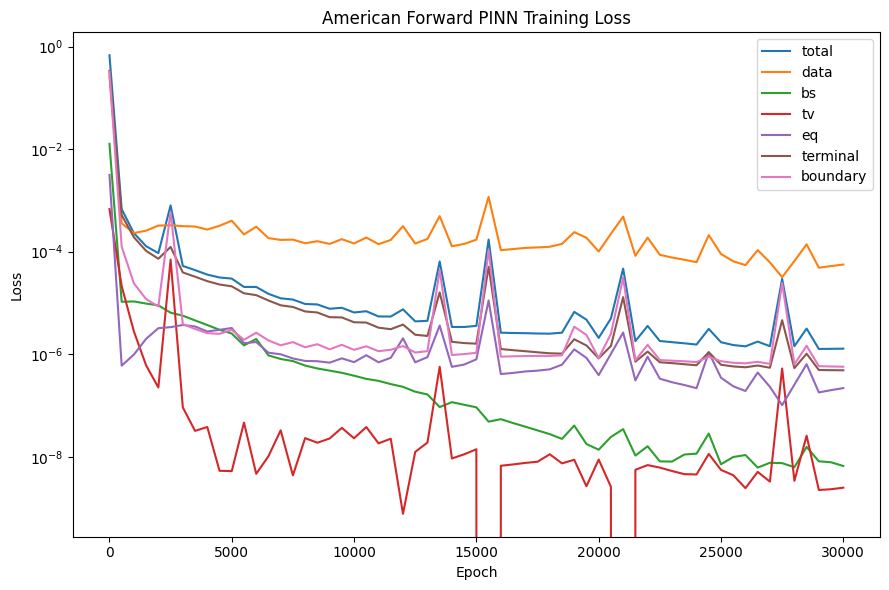

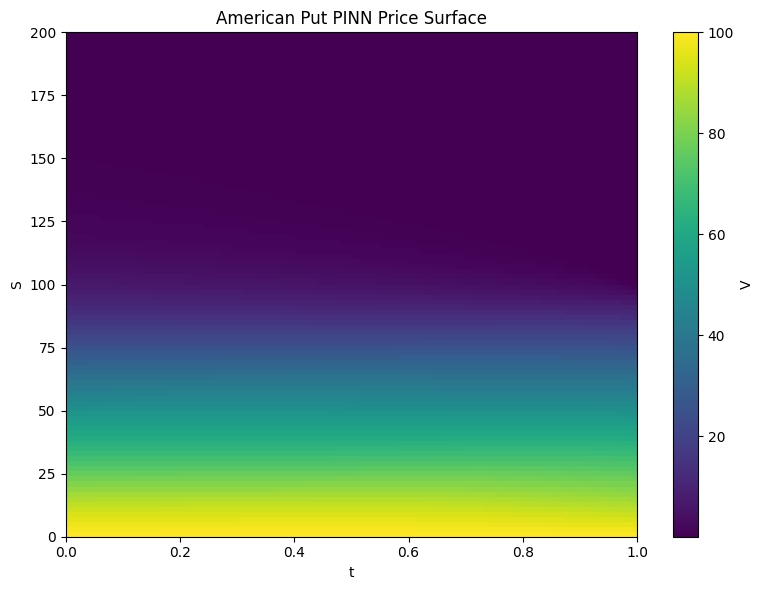

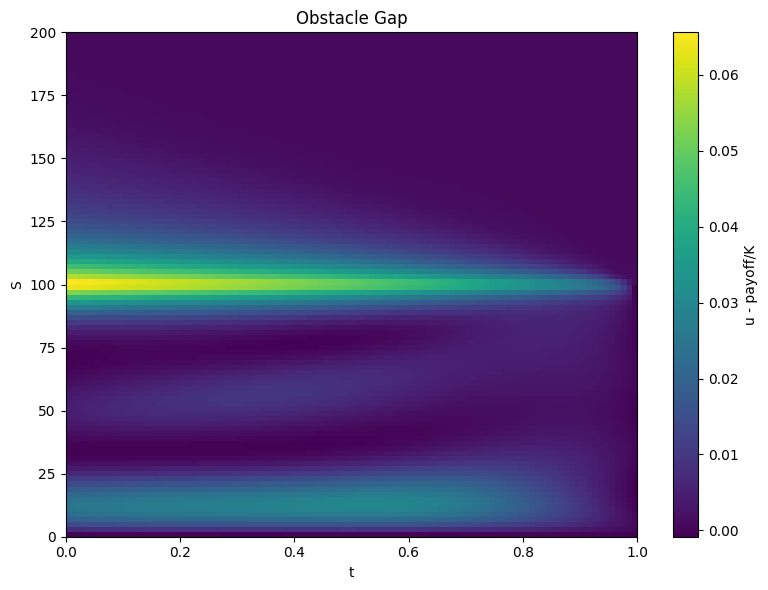

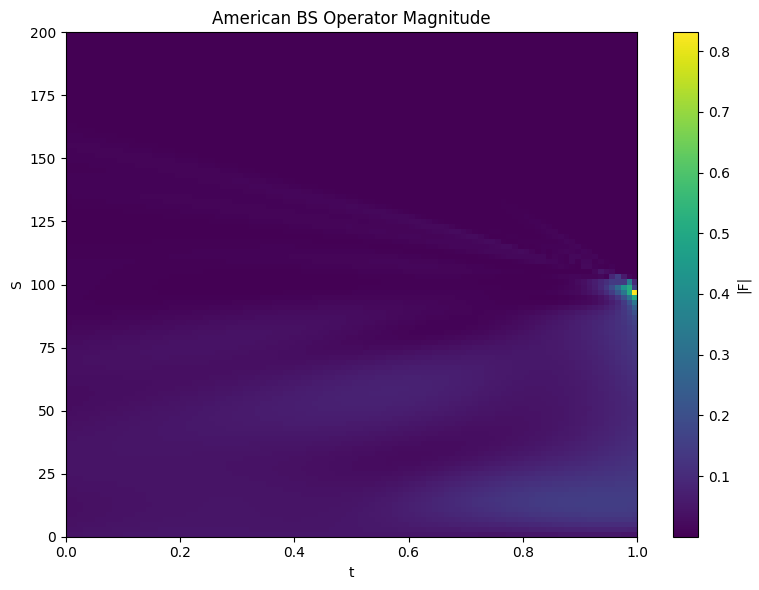

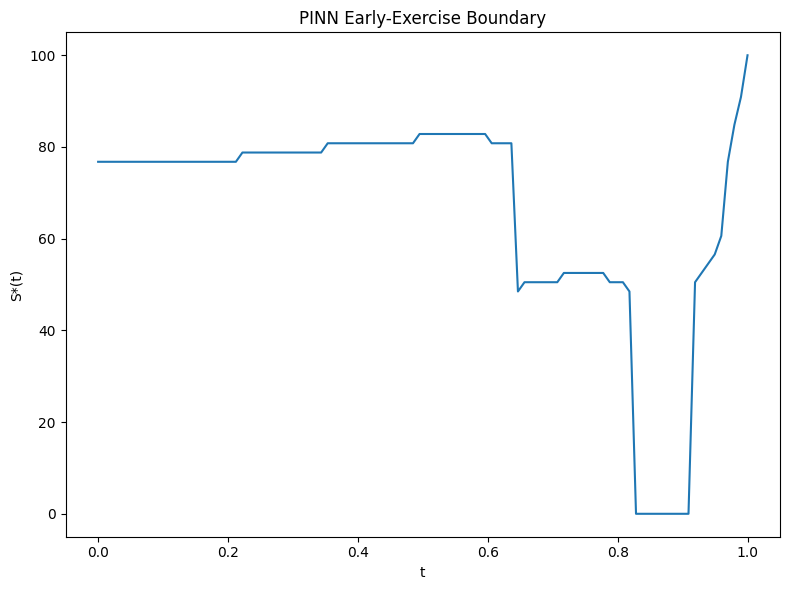

In [13]:
# Training losses
plt.figure(figsize=(9, 6))
for col in ["total", "data", "bs", "tv", "eq", "terminal", "boundary"]:
    plt.semilogy(history_df["epoch"], history_df[col], label=col)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("American Forward PINN Training Loss")
plt.legend()
plt.tight_layout()
plt.show()

# PINN price surface
plt.figure(figsize=(8, 6))
plt.imshow(
    V_grid.T,
    origin="lower",
    aspect="auto",
    extent=[0.0, T, S_min, S_max]
)
plt.colorbar(label="V")
plt.xlabel("t")
plt.ylabel("S")
plt.title("American Put PINN Price Surface")
plt.tight_layout()
plt.show()

# Obstacle gap
plt.figure(figsize=(8, 6))
plt.imshow(
    gap_u.T,
    origin="lower",
    aspect="auto",
    extent=[0.0, T, S_min, S_max]
)
plt.colorbar(label="u - payoff/K")
plt.xlabel("t")
plt.ylabel("S")
plt.title("Obstacle Gap")
plt.tight_layout()
plt.show()

# Operator magnitude
plt.figure(figsize=(8, 6))
plt.imshow(
    np.abs(F_grid).T,
    origin="lower",
    aspect="auto",
    extent=[0.0, T, S_min, S_max]
)
plt.colorbar(label="|F|")
plt.xlabel("t")
plt.ylabel("S")
plt.title("American BS Operator Magnitude")
plt.tight_layout()
plt.show()

# PINN boundary
plt.figure(figsize=(8, 6))
plt.plot(t_eval_np, B_pinn)
plt.xlabel("t")
plt.ylabel("S*(t)")
plt.title("PINN Early-Exercise Boundary")
plt.tight_layout()
plt.show()
